<center><h1>Xie_Anna_HW6</h1></center>

Name: Anna Xie
<br>
Github Username: annajxie 
<br>
USC ID: 2277255370

## 1. Tree-Based Methods

Import packages

In [14]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer

### (a) Download the APS Failure data

In [3]:
path_test = '../data/aps_failure_test_set.csv'
path_train = '../data/aps_failure_training_set.csv'
df_train = pd.read_csv(path_train, header=14, sep=',')
df_test = pd.read_csv(path_test, header=14, sep=',')

# checking that training is 60,000 rows, 
# 1000 positive and 171 columns
# all attributes are numeric
print(df_train.shape)
print(df_train.head())
print(df_train.columns)

(60000, 171)
  class  aa_000 ab_000      ac_000 ad_000 ae_000 af_000 ag_000 ag_001 ag_002  \
0   neg   76698     na  2130706438    280      0      0      0      0      0   
1   neg   33058     na           0     na      0      0      0      0      0   
2   neg   41040     na         228    100      0      0      0      0      0   
3   neg      12      0          70     66      0     10      0      0      0   
4   neg   60874     na        1368    458      0      0      0      0      0   

   ...   ee_002  ee_003  ee_004  ee_005  ee_006  ee_007  ee_008 ee_009 ef_000  \
0  ...  1240520  493384  721044  469792  339156  157956   73224      0      0   
1  ...   421400  178064  293306  245416  133654   81140   97576   1500      0   
2  ...   277378  159812  423992  409564  320746  158022   95128    514      0   
3  ...      240      46      58      44      10       0       0      0      4   
4  ...   622012  229790  405298  347188  286954  311560  433954   1218      0   

  eg_000  
0      0

### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Different techniques are used for different missing data categories. If the missing data is not random, completely random, or random, then the context that caused the data to be missing will differ; chance accident of the data collection, a systematic error, or a purposeful ommittance. For missing data completely at random, deleting the rows is usually how you handle it beaause the data being missing has no relationship with any observed or unobserved data. For data missing at random which is systematically related to other observed variables, you usually do multiple imputation or MLE to get unbiased results. For data missing not at random where there's the missing data is directly related to the unobserved value, handling usually means selection models or personal deduction based on deep subject-based knowledge on the data itself. 
The APS dataset is anonymized sensor and counter readings so the missing data is most likely from a sensor not recording anything. I think if the column has over 50-70% missing, the feature columns should be dropped and the rest of the missing data values can be imputed to the medium as a baseline.

#### (ii) Calculate the coefficient of variation

In [4]:
# do imputation now?
# load the missing values tracker into another col so i can calculate just how much data is missing
# is the missing data where the data is 0?
features = df_train.drop(columns='class')
na_rate = (features == 'na').mean()
# missing_rate = features.isna().mean() # there's no isna() data values

summary = pd.DataFrame({'na_rate': na_rate})
# print(summary.sort_values('na_rate', ascending=False).head(15)) 
# each columns has some % of na values 

# convert from string to null value
df_test = df_test.replace('na', np.nan)
df_train = df_train.replace('na', np.nan)
features = [c for c in df_train.columns if c != 'class']
df_test[features] = df_test[features].astype(float)
df_train[features] = df_train[features].astype(float)
# print(df_train.head(5))

y_train = (df_train['class'] == 'pos').astype(int)
y_test = (df_test['class'] == 'pos').astype(int)

# drop columns that are 50%> on training set
na_rate = df_train[features].isna().mean()
to_drop = na_rate[na_rate > 0.5].index.tolist()
# print(len(to_drop), 'columns dropped: ', to_drop)

keep = [c for c in features if c not in to_drop]
X_train, X_test = df_train[keep], df_test[keep]

# median imputation on both datasets
imp = SimpleImputer(strategy='median')
X_train_imp = pd.DataFrame(imp.fit_transform(X_train), columns=keep, index=X_train.index)
X_test_imp = pd.DataFrame(imp.fit_transform(X_test), columns=keep, index=X_test.index)

# CV = s/m
# s = standard deviation
# m = sample mean
s = X_train_imp.std(ddof=1)
m = X_train_imp.mean()

cv = s/m 
cv_ranked = cv.dropna().sort_values(ascending=False)
print("Coefficient of Variation per Col:")
print(cv_ranked.head(15))

Coefficient of Variation per Col:
cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
dj_000    117.494225
ag_000     92.917755
as_000     87.332500
ay_009     84.733735
ak_000     80.424975
az_009     77.838544
ch_000     77.453857
au_000     68.882751
ay_001     52.824714
df_000     52.292814
dtype: float64


#### (iii) Plot a correlation matrix

In [5]:
# plot a correlation matrix for features
corr = X_train_imp.corr(numeric_only = True)
print(corr)

          aa_000    ac_000    ad_000    ae_000    af_000    ag_000    ag_001  \
aa_000  1.000000 -0.063876 -0.001590  0.043095  0.062855  0.018549  0.142645   
ac_000 -0.063876  1.000000 -0.001765 -0.004250 -0.009480  0.017155 -0.007334   
ad_000 -0.001590 -0.001765  1.000000 -0.000168 -0.000209 -0.000043 -0.000115   
ae_000  0.043095 -0.004250 -0.000168  1.000000  0.823123 -0.000445 -0.001072   
af_000  0.062855 -0.009480 -0.000209  0.823123  1.000000 -0.000553 -0.001319   
...          ...       ...       ...       ...       ...       ...       ...   
ee_007  0.603888 -0.048648 -0.000801  0.035503  0.047858  0.000329  0.044185   
ee_008  0.469836 -0.003714 -0.001235 -0.009632 -0.012347 -0.000787  0.004927   
ee_009  0.247149  0.013764 -0.000716 -0.007218 -0.008996 -0.001209 -0.004274   
ef_000  0.012409 -0.006262 -0.000082  0.070869  0.106312 -0.000078  0.001793   
eg_000  0.024387  0.014747 -0.000096  0.041725  0.060756  0.000236  0.007453   

          ag_002    ag_003    ag_004  .

#### (iv) Make scatter plots and box plots

['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


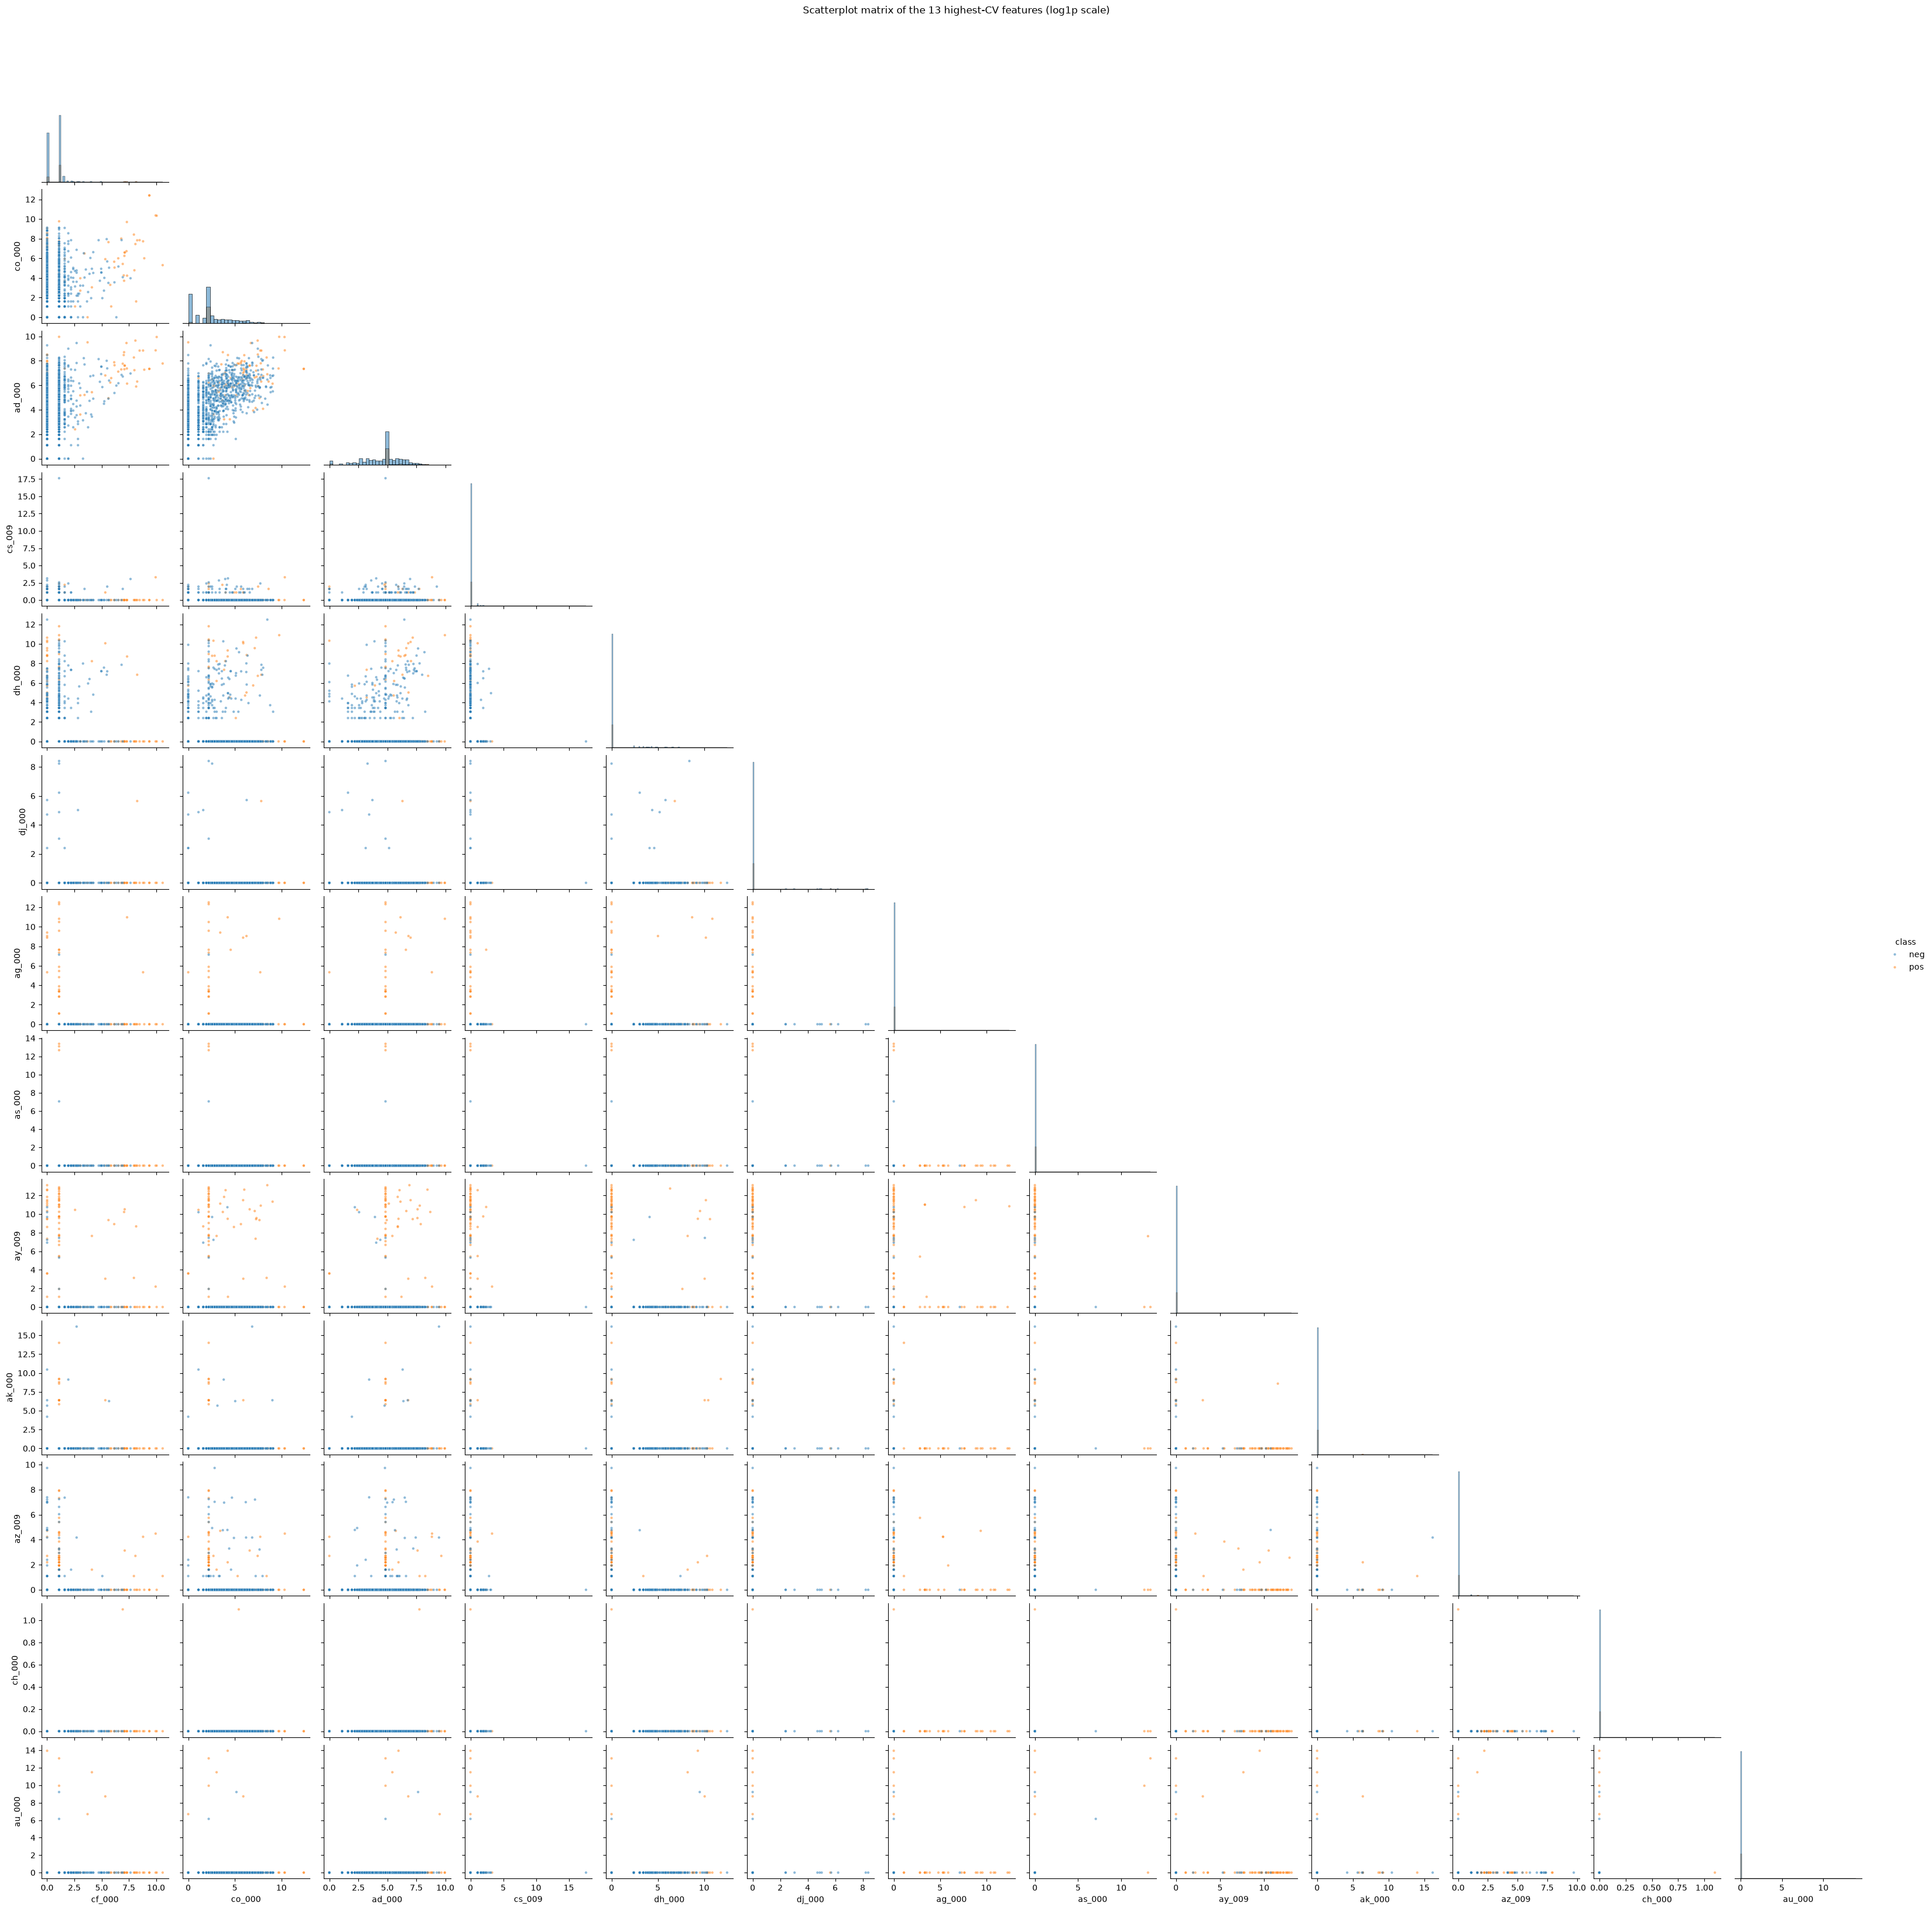

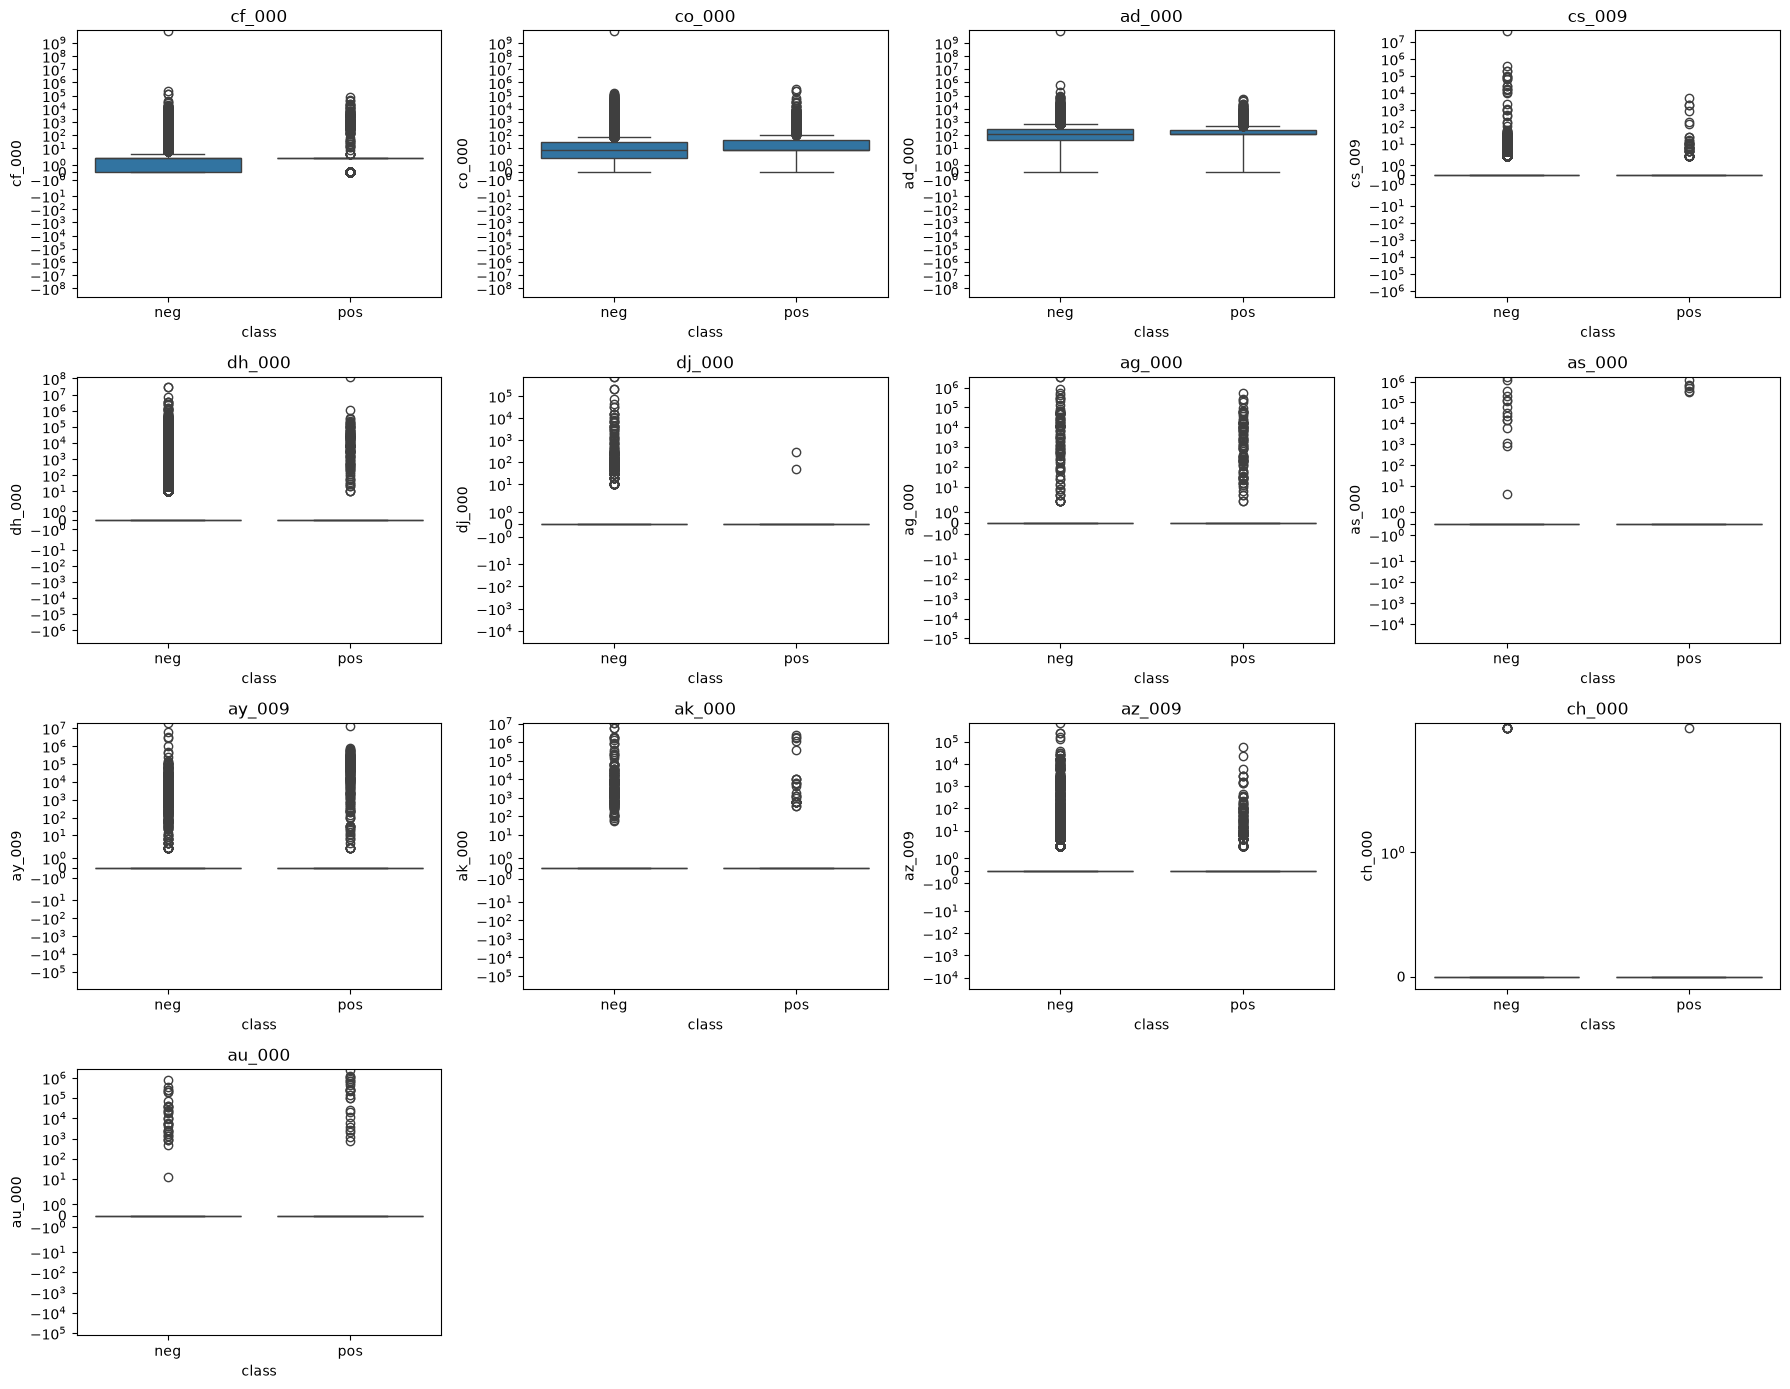

answer question here


In [18]:
# square root of 170 features with highest CV
k = int(np.floor(np.sqrt(170)))                  # 13
top_features = cv_ranked.iloc[:k].index.tolist()
print(top_features)

plot_df = X_train_imp[top_features].assign(**{'class': y_train.map({0: 'neg', 1: 'pos'}).values})

# log1p for plotting only: the features are heavy-tailed and mostly zero
log_df = plot_df.copy()
log_df[top_features] = np.log1p(log_df[top_features])

# oversample positives so both classes are visible
sample = pd.concat([
    log_df[log_df['class'] == 'pos'].sample(300, random_state=0),
    log_df[log_df['class'] == 'neg'].sample(1500, random_state=0),
])

# scatterplot matrix
g = sns.pairplot(sample, vars=top_features, hue='class', hue_order=['neg', 'pos'],
                 plot_kws={'s': 10, 'alpha': 0.5}, diag_kind='hist', corner=True)
g.fig.suptitle('Scatterplot matrix of the 13 highest-CV features (log1p scale)', y=1.01)
plt.show()

# box plots, one per feature
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, f in zip(axes.flatten(), top_features):
    sns.boxplot(data=plot_df, x='class', y=f, ax=ax)
    ax.set_yscale('symlog')
    ax.set_title(f)
for ax in axes.flatten()[len(top_features):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

# question: can you draw conclusion about significance of those features, just by scatter plots?
print("The plots show that some features, such as ag_000, as_000, ay_009 and au_000, have unusually large values mostly among failures, and that co_000 and ad_000 rise together. That’s suggestive, but a scatter plot gives no test statistic or p-value, so it can’t establish significance. Most of these features are zero for nearly every truck, and only about 1.7% of the data is positive, so visual separation is hard to judge and a few points can look convincing by chance. Pairs of features can also look uninformative on their own and still matter in a model, and features picked for high CV are chosen for variability, not for relevance to failure. To claim significance we’d need a formal test or model-based importance.")


#### (v) Is this data set imbalanced?

In [7]:
# how to see if dataset imbalanced?
# see label (class) counts and proportions 
counts = df_train['class'].value_counts()
proportions = df_train['class'].value_counts(normalize=True) * 100
print(counts)
print(proportions)

print("Yes the dataset is imbalanced.")

# print(X_train_imp.shape, y_train.shape)    # expect (60000, ...) and (60000,)
# print(X_test_imp.shape,  y_test.shape)     # expect (16000, ...) and (16000,) -- yours is probably 60000
# print(df_train.shape, df_test.shape)


class
neg    59000
pos     1000
Name: count, dtype: int64
class
neg    98.333333
pos     1.666667
Name: proportion, dtype: float64
Yes the dataset is imbalanced.


### (c) Train a random forest

train confusion matrix: 
 [[59000     0]
 [    0  1000]]
test confusion matrix: 
 [[15607    18]
 [  103   272]]
Train misclassification: 0.0000
Test misclassification: 0.0076
Test sensitivity: 0.7253 specificity: 0.9988
Train AUC: 1.0000   Test AUC: 0.9943
OOB error: 0.0060   test error: 0.0076


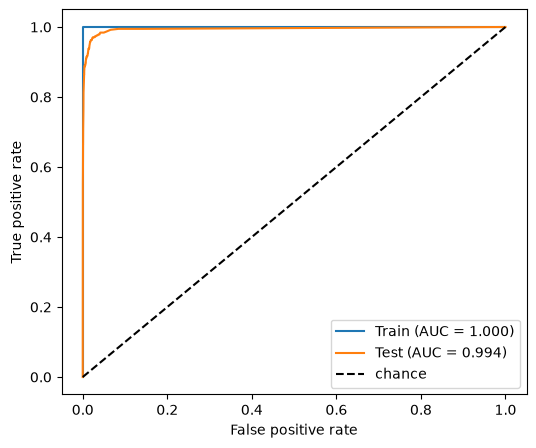

In [8]:
# train random forest to classify dataset
# do not compensate for class imbalance
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=0, n_jobs=-1)
rf.fit(X_train_imp, y_train)


pred_train = rf.predict(X_train_imp)
proba_train = rf.predict_proba(X_train_imp)[:,1]
pred_test = rf.predict(X_test_imp)
proba_test = rf.predict_proba(X_test_imp)[:,1]

# do confusion matric, ROC, AUC, and misclassification for training + test sets and report them
# calculate out of bag error estimate for random forest and compare to test error 
cm_train = confusion_matrix(y_train, pred_train)
cm_test = confusion_matrix(y_test, pred_test)
print("train confusion matrix: \n", cm_train)
print("test confusion matrix: \n", cm_test)

# misclassification rate
err_train = 1 - accuracy_score(y_train, pred_train)
err_test = 1 - accuracy_score(y_test, pred_test)
print(f"Train misclassification: {err_train:.4f}")
print(f"Test misclassification: {err_test:.4f}")

# sensitivity
tn, fp, fn, tp = cm_test.ravel()
print(f"Test sensitivity: {tp/(tp+fn):.4f} specificity: {tn/(tn+fp):.4f}")

# AUC
auc_train = roc_auc_score(y_train, proba_train)
auc_test = roc_auc_score(y_test, proba_test)
print(f"Train AUC: {auc_train:.4f}   Test AUC: {auc_test:.4f}") 

# ROC curves
fpr_train, tpr_train, _ = roc_curve(y_train, proba_train)
fpr_test, tpr_test, _ = roc_curve(y_test, proba_test)

fig, ax = plt.subplots(1,1, figsize=(6,5))
ax.plot(fpr_train, tpr_train, label=f'Train (AUC = {auc_train:.3f})')
ax.plot(fpr_test, tpr_test, label=f"Test (AUC = {auc_test:.3f})")
ax.plot([0,1], [0,1], 'k--', label='chance')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.legend()

oob_error = 1 - rf.oob_score_
print(f"OOB error: {oob_error:.4f}   test error: {err_test:.4f}")

### (d) Imbalance

In random forests, class imbalance is usually handled with either undersampling the data or cost-sensitive learning where you give the minority class a higher weight so errors cost more.
I'm implementing a class_weight hyperparam where the errors on the minority class count more.
I'm also implementing a balanced random forest where each tree trains on a down-sampled majority dataset.


c:\Users\annax\anaconda3\Lib\site-packages\imblearn\ensemble\_forest.py:827: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


RF (no compensation): OOB error = 0.0060
RF weighted: OOB error = 0.0075
RF balanced: OOB error = 0.0446


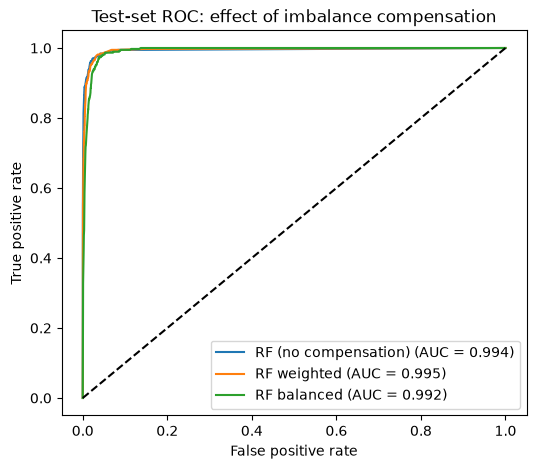

               model   set    TN   FP  FN   TP  misclassification  sensitivity  specificity    AUC
RF (no compensation) train 59000    0   0 1000             0.0000       1.0000       1.0000 1.0000
RF (no compensation)  test 15607   18 103  272             0.0076       0.7253       0.9988 0.9943
         RF weighted train 59000    0   0 1000             0.0000       1.0000       1.0000 1.0000
         RF weighted  test 15612   13 154  221             0.0104       0.5893       0.9992 0.9946
         RF balanced train 56141 2859  11  989             0.0478       0.9890       0.9515 0.9962
         RF balanced  test 14892  733   8  367             0.0463       0.9787       0.9531 0.9922


In [9]:
# research how class imbalance is addressed in random forests
print("In random forests, class imbalance is usually handled with either undersampling the data or cost-sensitive learning where you give the minority class a higher weight so errors cost more.")

# compensate for the class imbalance in random forest and repeat the prev training steps
print("I'm implementing a class_weight hyperparam where the errors on the minority class count more.")
rf_w = RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample', oob_score=True, random_state=0, n_jobs=-1)
rf_w.fit(X_train_imp, y_train)

print("I'm also implementing a balanced random forest where each tree trains on a down-sampled majority dataset.")
rf_b = BalancedRandomForestClassifier(n_estimators=300, oob_score=True, bootstrap=True, random_state=0, n_jobs=-1)
rf_b.fit(X_train_imp, y_train)

# compare results w prev step's results
models = {'RF (no compensation)': rf, 'RF weighted': rf_w, 'RF balanced': rf_b}
rows = []
fig, ax = plt.subplots(1, 1, figsize=(6, 5))

for name, m in models.items():
    for split, X, y in [('train', X_train_imp, y_train), ('test', X_test_imp, y_test)]:
        pred, proba = m.predict(X), m.predict_proba(X)[:, 1]
        tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
        rows.append({'model': name, 'set': split, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                     'misclassification': 1 - accuracy_score(y, pred),
                     'sensitivity': tp / (tp + fn), 'specificity': tn / (tn + fp),
                     'AUC': roc_auc_score(y, proba)})
        if split == 'test':
            fpr, tpr, _ = roc_curve(y, proba)
            ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y, proba):.3f})")
    print(f"{name}: OOB error = {1 - m.oob_score_:.4f}")

ax.plot([0, 1], [0, 1], 'k--')
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
ax.set_title('Test-set ROC: effect of imbalance compensation'); ax.legend(); plt.show()

results = pd.DataFrame(rows)
print(results.round(4).to_string(index=False))

### (e) XGBoost and Model Trees

best alpha: 0.1 | CV AUC: 0.987
train confusion matrix:
 [[58461   539]
 [   77   923]]
test confusion matrix:
 [[15389   236]
 [   33   342]]
misclassification  train: 0.0103  test: 0.0168  5-fold CV: 0.0125
AUC  train: 0.9968  test: 0.9929


Text(0.5, 1.0, 'Test-set ROC: effect of SMOTE')

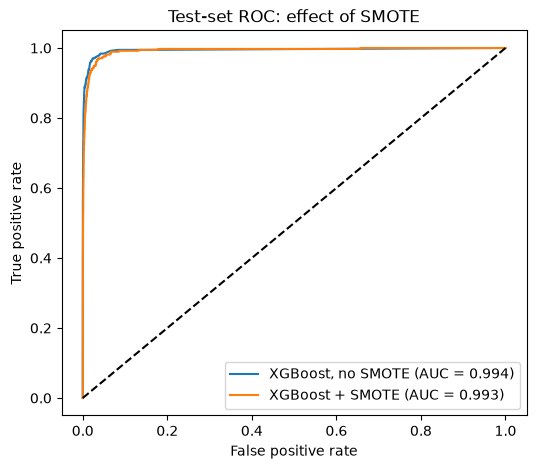

In [15]:
# i'm not pasting the whole paragraph but just know i'm crashing out
xgb = XGBClassifier(objective='binary:logistic', n_estimators=200, learning_rate=0.1,
                    max_depth=3, subsample=0.8, tree_method='hist',
                    eval_metric='logloss', random_state=0, n_jobs=-1)
                    # no scale_pos_weight: no imbalance compensation in this part

# choose alpha (reg_alpha, the L1 penalty) by 5-fold stratified CV
cv = StratifiedKFold(5, shuffle=True, random_state=0)
grid = GridSearchCV(xgb, {'reg_alpha': [0, 0.01, 0.1, 1, 10, 100]},
                    cv=cv, scoring='roc_auc', n_jobs=1)    # n_jobs=1 here: xgb already uses all cores
grid.fit(X_train_imp, y_train)
best = grid.best_estimator_
print("best alpha:", grid.best_params_['reg_alpha'], "| CV AUC:", round(grid.best_score_, 4))

# CV estimate of the misclassification error at the chosen alpha, to compare with test error
cv_err = 1 - cross_val_score(best, X_train_imp, y_train, cv=cv, scoring='accuracy').mean()

# train/test metrics
pred_train, proba_train = best.predict(X_train_imp), best.predict_proba(X_train_imp)[:, 1]
pred_test,  proba_test  = best.predict(X_test_imp),  best.predict_proba(X_test_imp)[:, 1]

print("train confusion matrix:\n", confusion_matrix(y_train, pred_train))
print("test confusion matrix:\n",  confusion_matrix(y_test,  pred_test))
err_train, err_test = 1 - accuracy_score(y_train, pred_train), 1 - accuracy_score(y_test, pred_test)
print(f"misclassification  train: {err_train:.4f}  test: {err_test:.4f}  5-fold CV: {cv_err:.4f}")
auc_train, auc_test = roc_auc_score(y_train, proba_train), roc_auc_score(y_test, proba_test)
print(f"AUC  train: {auc_train:.4f}  test: {auc_test:.4f}")

fpr_tr, tpr_tr, _ = roc_curve(y_train, proba_train)
fpr_te, tpr_te, _ = roc_curve(y_test,  proba_test)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr_tr, tpr_tr, label=f'Train (AUC = {auc_train:.3f})')
ax.plot(fpr_te, tpr_te, label=f'Test (AUC = {auc_test:.3f})')
ax.plot([0, 1], [0, 1], 'k--'); ax.legend()
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
ax.set_title('XGBoost (L1-penalized), no imbalance compensation'); plt.show()

### (f) Use SMOTE to pre-process your data

In [ ]:
# use synthetic minority oversampling technique to pre-process your data to compensate for class imbalance
# train xgboost with l1-penalized logistic regression at each node using the pre-processed data and repeate prev step
# there is a right and wrong way to cross validate
# compare uncompensated case w smote case

pipe = Pipeline([
    ('smote', SMOTE(random_state=0)),
    ('xgb', XGBClassifier(objective='binary:logistic', n_estimators=200, learning_rate=0.1,
                          max_depth=3, subsample=0.8, tree_method='hist',
                          eval_metric='logloss', random_state=0, n_jobs=-1)),
])

# choose alpha by 5-fold CV; SMOTE is refit on the training part of every fold
cv = StratifiedKFold(5, shuffle=True, random_state=0)
grid_s = GridSearchCV(pipe, {'xgb__reg_alpha': [0, 0.1, 1, 10]},
                      cv=cv, scoring='roc_auc', n_jobs=1)
grid_s.fit(X_train_imp, y_train)       # refits the best pipeline on the full SMOTE'd training set
best_s = grid_s.best_estimator_
print("best alpha:", grid_s.best_params_['xgb__reg_alpha'], "| CV AUC:", round(grid_s.best_score_, 4))

# CV estimate of the misclassification error (validation folds are NOT resampled)
cv_err_s = 1 - cross_val_score(best_s, X_train_imp, y_train, cv=cv, scoring='accuracy').mean()

# metrics on the original (not SMOTE'd) training data and the untouched test data
pred_train_s, proba_train_s = best_s.predict(X_train_imp), best_s.predict_proba(X_train_imp)[:, 1]
pred_test_s,  proba_test_s  = best_s.predict(X_test_imp),  best_s.predict_proba(X_test_imp)[:, 1]

print("train confusion matrix:\n", confusion_matrix(y_train, pred_train_s))
print("test confusion matrix:\n",  confusion_matrix(y_test,  pred_test_s))
err_train_s = 1 - accuracy_score(y_train, pred_train_s)
err_test_s  = 1 - accuracy_score(y_test,  pred_test_s)
print(f"misclassification  train: {err_train_s:.4f}  test: {err_test_s:.4f}  5-fold CV: {cv_err_s:.4f}")
auc_train_s, auc_test_s = roc_auc_score(y_train, proba_train_s), roc_auc_score(y_test, proba_test_s)
print(f"AUC  train: {auc_train_s:.4f}  test: {auc_test_s:.4f}")

# ROC: SMOTE vs no SMOTE on the test set (uses proba_test from your 1(e) cell)
fpr_a, tpr_a, _ = roc_curve(y_test, proba_test)
fpr_b, tpr_b, _ = roc_curve(y_test, proba_test_s)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr_a, tpr_a, label=f'XGBoost, no SMOTE (AUC = {roc_auc_score(y_test, proba_test):.3f})')
ax.plot(fpr_b, tpr_b, label=f'XGBoost + SMOTE (AUC = {auc_test_s:.3f})')
ax.plot([0, 1], [0, 1], 'k--')
ax.legend()
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('Test-set ROC: effect of SMOTE')

## 2. ISLR 6.6.3

a.) The training RSS will steadily decrease. A larger s allows every solution that was allowed before plus more, so the minimum RSS goes down because of the added diversity. 

b.) The testing RSS will decrease intiially then eventually increase in a U shape. The increased flexibility will remove bias so the RSS will go down but th emodel will start fitting to use by overfitting will begin increasing RSS again. 

c.) The variance will steadily increase. Higher s means the constraint noted loosens and the model grows more flexibility. A more flexible fit varies more across training sets.

d.) The squared bias will steadily increase because increasing s means higher flexibility and as the model's output fit closers to the truth the bias will decrease.

e.) The irreducible error remains constant because in a model, the irreducible error is the aspect of the algorithm that is random and always unexplainable by the algorithm. Because the error is unknown, there's no control for it and therefore remains constant no matter the adjustments you make. 

## 3. ISLR 6.6.5

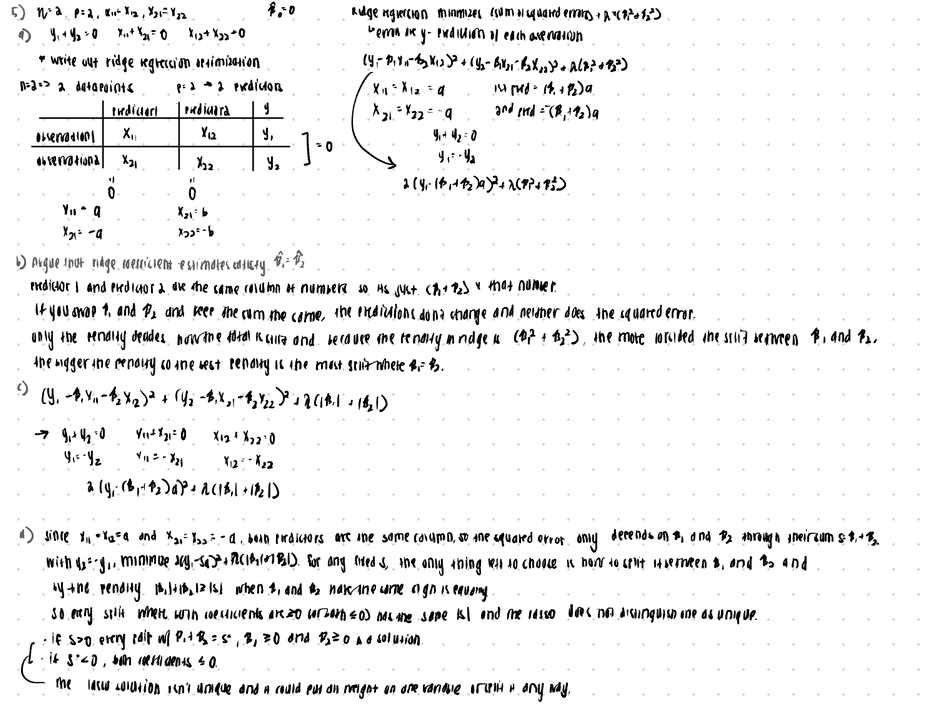

## 4. ISLR 8.4.5

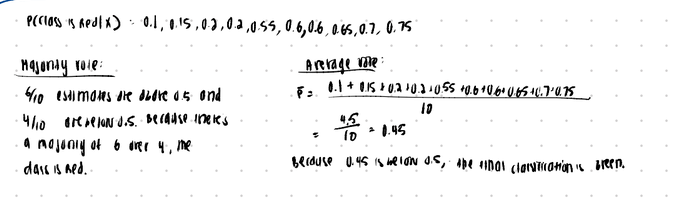

## 5. ISLR 9.7.3

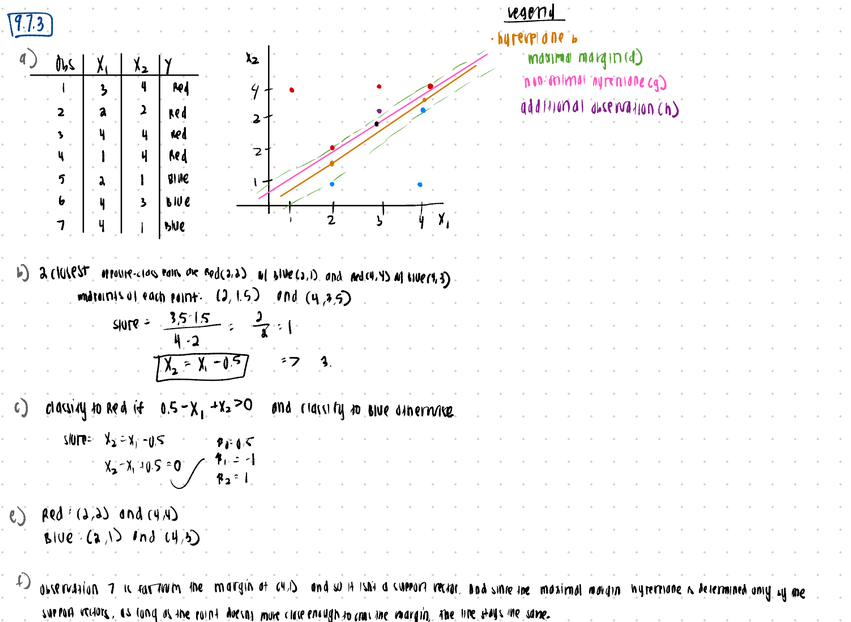